# Student At-Risk Identification: Support Vector Machine (refactored)

IT3091 Machine Learning | Group 2026-AI-53

**Objective:** Train and evaluate Support Vector Machine (SVM) classifiers on the UCI Student Performance datasets (Mathematics and Portuguese) to identify students at risk of poor academic performance, show what tuning changes, and describe what the fitted models look like.

**Methodology (unchanged from the original notebook):**
- Target: **At-Risk = 1 when `G3 < 10`**, otherwise Not-At-Risk = 0.
- Inputs: every column except `G1`, `G2`, `G3`, so grades are never used to predict grades.
- Mathematics and Portuguese are modelled **separately**.
- Stratified 80/20 split, `random_state=42`.
- Preprocessing: median imputation and `StandardScaler` for numeric columns, most-frequent imputation and one-hot encoding for categorical columns, all inside a `Pipeline`.
- Baseline: `SVC(kernel="rbf", C=1.0, class_weight=None, probability=True, random_state=42)`.
- Tuning: `GridSearchCV` over `kernel` (linear, rbf), `C` (0.1, 1, 10) and `class_weight` (None, balanced), 5-fold stratified CV, scored by F1, on the training data only.

**Workflow:** Step 1 Setup and loading, Step 2 EDA, Step 3 Target and features, Step 4 Split and preprocessing, Step 5 Baseline, Step 6 Tuning, Step 7 Tuned evaluation, Step 8 Baseline versus tuned, Step 9 What the SVM learned, Step 10 Final results, Step 11 Optional comparison with Logistic Regression.

Every conclusion printed in Steps 5 to 11 is computed from the current run, so it updates if the notebook is re-run.

## Step 1: Setup and data loading

- **What are we doing?** Importing every library once, defining all settings and paths in one cell, and loading both CSV files once.
- **Why?** One configuration cell stops the seed, paths and column lists from drifting between cells, and loading once guarantees every later step uses identical data.
- **What does the code produce?** The shape and column check for each dataset.
- **How to interpret it?** Both files should have 33 columns with identical names. The Portuguese file has more rows.
- **What happens next?** Step 2 inspects data quality and distributions.

In [1]:
from pathlib import Path

import joblib
from scipy.sparse import issparse
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    PrecisionRecallDisplay, RocCurveDisplay,
    accuracy_score, average_precision_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

# ---- Experiment settings (the only place these are defined) ----
RANDOM_STATE = 42           # same seed for the split, CV folds and the SVC probability estimates
TEST_SIZE = 0.20
CV_SPLITS = 5
TARGET_COLUMN = "G3"
RISK_THRESHOLD = 10         # G3 below this value means At-Risk
EXCLUDED_FEATURES = ["G1", "G2", "G3"]    # grades are never used as predictors
SUBJECTS = ["Mathematics", "Portuguese"]
FILE_NAMES = {"Mathematics": "student-mat.csv", "Portuguese": "student-por.csv"}
CLASS_NAMES = ["Not-At-Risk", "At-Risk"]
METRICS = ["Accuracy", "At-Risk Precision", "At-Risk Recall", "At-Risk F1", "ROC-AUC"]
SAVE_OUTPUTS = True         # set False to skip writing models and CSV reports

# ---- Paths (the only place these are defined) ----
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif not (ROOT / "data" / "raw").exists() and (ROOT / "student-risk-intelligence" / "data" / "raw").exists():
    ROOT = ROOT / "student-risk-intelligence"

DATA_DIR = ROOT / "data" / "raw"
MODEL_DIR = ROOT / "notebooks" / "models"
REPORT_DIR = ROOT / "notebooks" / "reports"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

print("Project root:", ROOT.resolve())
print("Data directory:", DATA_DIR.resolve())

Project root: C:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project
Data directory: C:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project\data\raw


In [2]:
# Load each CSV once. The UCI files are semicolon separated.
missing_files = [DATA_DIR / FILE_NAMES[s] for s in SUBJECTS if not (DATA_DIR / FILE_NAMES[s]).exists()]
if missing_files:
    raise FileNotFoundError(
        "Missing dataset file(s):\n" + "\n".join(str(p) for p in missing_files)
        + "\nOpen the notebook from the project folder or update ROOT above."
    )

raw = {s: pd.read_csv(DATA_DIR / FILE_NAMES[s], sep=";") for s in SUBJECTS}

for s, df in raw.items():
    print(f"{s}: {df.shape[0]} rows x {df.shape[1]} columns")

print("\nColumns identical in both files:",
      raw["Mathematics"].columns.tolist() == raw["Portuguese"].columns.tolist())
print("\nColumns:", raw["Mathematics"].columns.tolist())

Mathematics: 395 rows x 33 columns
Portuguese: 649 rows x 33 columns

Columns identical in both files: True

Columns: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


## Step 2: Data understanding and exploratory data analysis

- **What are we doing?** Inspecting sample records, data types, statistics, data quality, class balance, distributions, and correlations.
- **Why?** EDA shows whether the classes are imbalanced (which makes accuracy misleading) and what the inputs look like. SVM is distance based, so the scale of each input matters, and the numeric predictors here are on very different ranges (age, absences, 1 to 5 scales). These charts describe the data and do not prove that any feature causes risk.
- **What does the code produce?** A quality table, sample rows, class balance with the `G3` distribution, numeric distributions, correlation with the At-Risk label, correlation between predictors, and at-risk rate by category.
- **How to interpret it?** The printed "Observation" lines under the charts are computed from the data.
- **What happens next?** Step 3 formally defines the target and predictors.

In [3]:
# Data quality summary and a first look at the records
quality = pd.DataFrame({
    s: {
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Numeric columns": df.select_dtypes(include="number").shape[1],
        "Categorical columns": df.select_dtypes(exclude="number").shape[1],
        "Missing values": int(df.isnull().sum().sum()),
        "Duplicate rows": int(df.duplicated().sum()),
        "Distinct G3 values": df["G3"].nunique(),
    }
    for s, df in raw.items()
})
display(quality)

for s, df in raw.items():
    print(f"\n{s}: first 3 records")
    display(df.head(3))
    print(f"{s}: descriptive statistics (numeric columns)")
    display(df.describe().T.round(2))

,Mathematics,Portuguese
Rows,395,649
Columns,33,33
Numeric columns,16,16
Categorical columns,17,17
Missing values,0,0
Duplicate rows,0,0
Distinct G3 values,18,17



Mathematics: first 3 records


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10


Mathematics: descriptive statistics (numeric columns)


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.75,1.09,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.04,0.84,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.11,1.11,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,1.0,2.0,5.0



Portuguese: first 3 records


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12


Portuguese: descriptive statistics (numeric columns)


,count,mean,std,min,25%,50%,75%,max
age,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


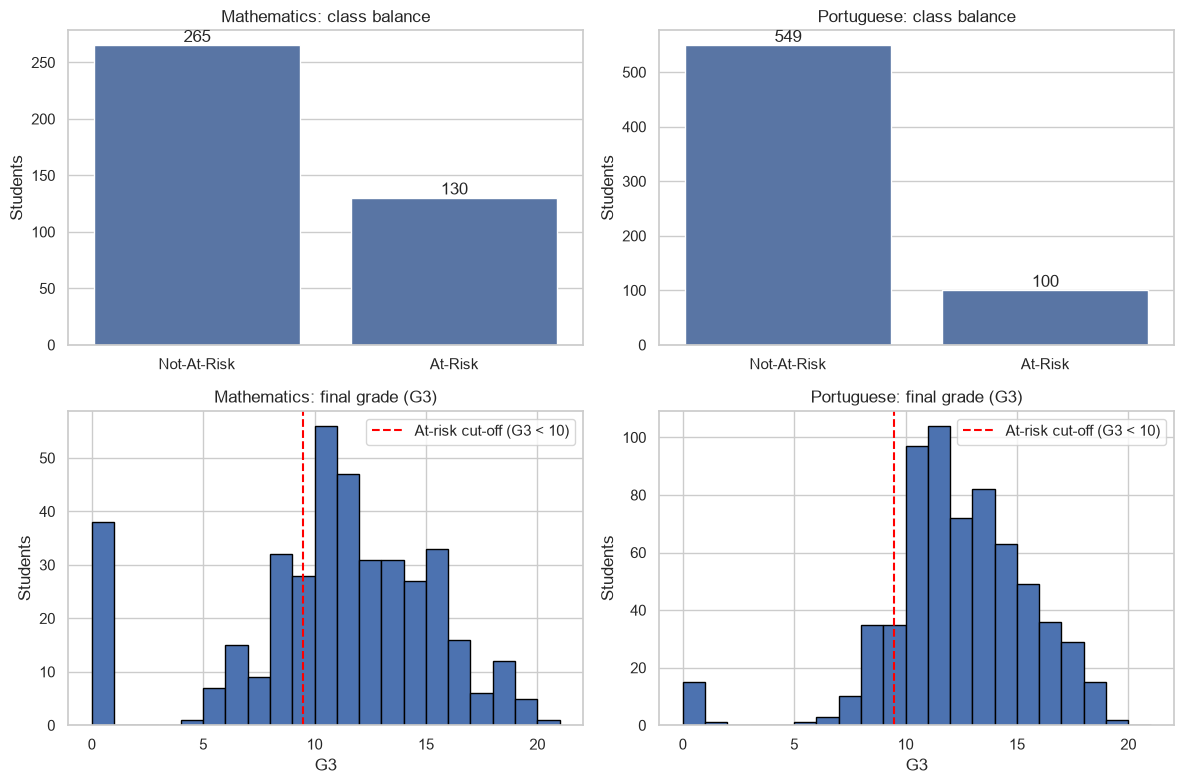

Observation: Mathematics: 32.9% of students are At-Risk.
Observation: Portuguese: 15.4% of students are At-Risk.
The At-Risk class is the minority in both subjects, so Precision, Recall and F1 for At-Risk matter more than Accuracy.


In [4]:
# Class balance and the G3 distribution relative to the at-risk cut-off
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, s in enumerate(SUBJECTS):
    df = raw[s]
    labels = (df[TARGET_COLUMN] < RISK_THRESHOLD).map({True: "At-Risk", False: "Not-At-Risk"})
    sns.countplot(x=labels, order=CLASS_NAMES, ax=axes[0, col])
    axes[0, col].set_title(f"{s}: class balance")
    axes[0, col].set_xlabel("")
    axes[0, col].set_ylabel("Students")
    for container in axes[0, col].containers:
        axes[0, col].bar_label(container)

    axes[1, col].hist(df[TARGET_COLUMN], bins=range(0, 22), edgecolor="black")
    axes[1, col].axvline(RISK_THRESHOLD - 0.5, color="red", linestyle="--", label=f"At-risk cut-off (G3 < {RISK_THRESHOLD})")
    axes[1, col].set_title(f"{s}: final grade (G3)")
    axes[1, col].set_xlabel("G3")
    axes[1, col].set_ylabel("Students")
    axes[1, col].legend()
plt.tight_layout()
plt.show()

for s in SUBJECTS:
    share = (raw[s][TARGET_COLUMN] < RISK_THRESHOLD).mean() * 100
    print(f"Observation: {s}: {share:.1f}% of students are At-Risk.")
print("The At-Risk class is the minority in both subjects, so Precision, Recall and F1 for At-Risk matter more than Accuracy.")

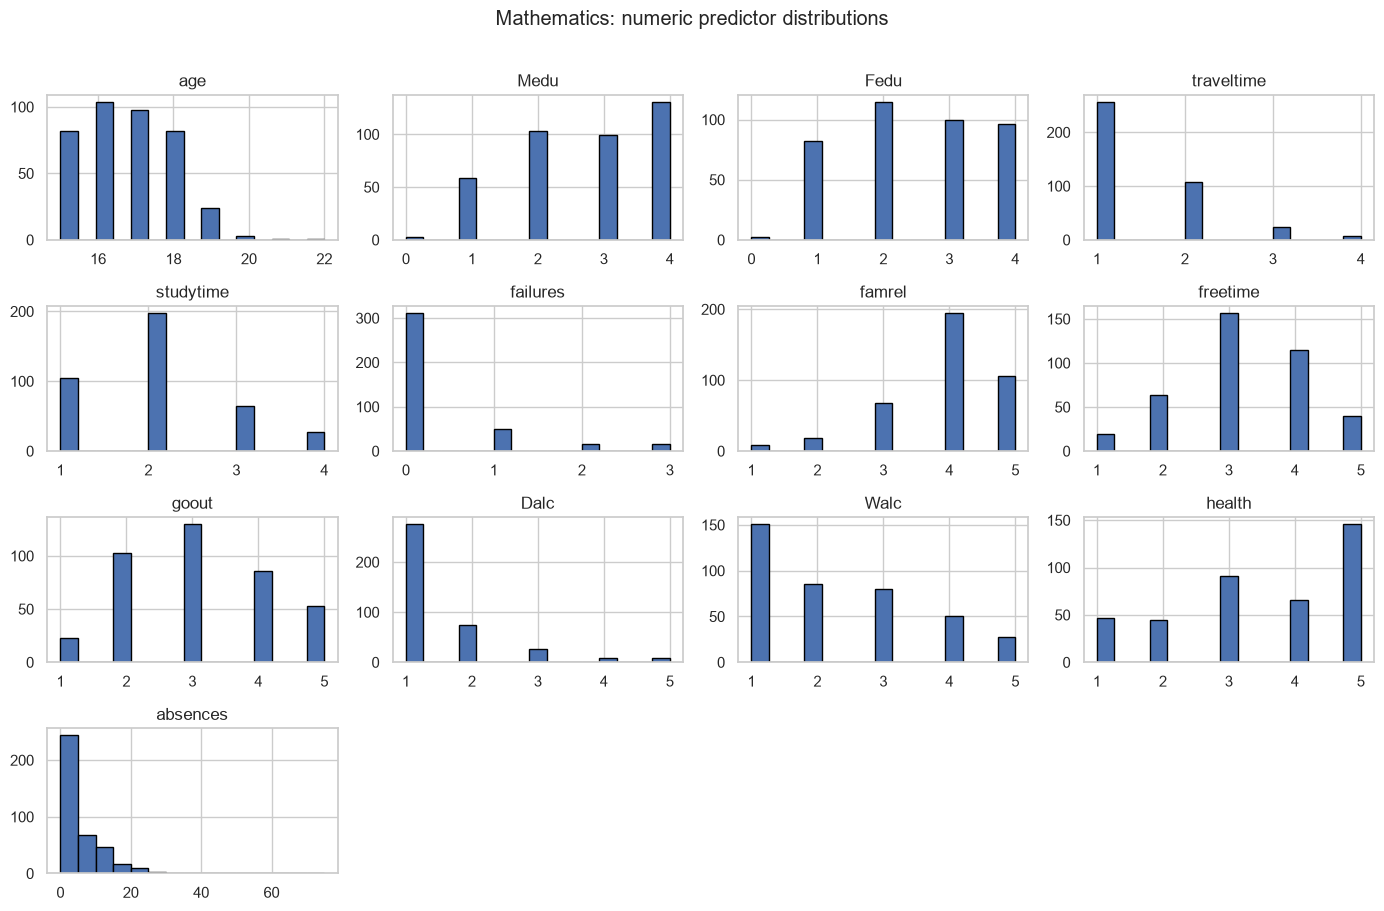

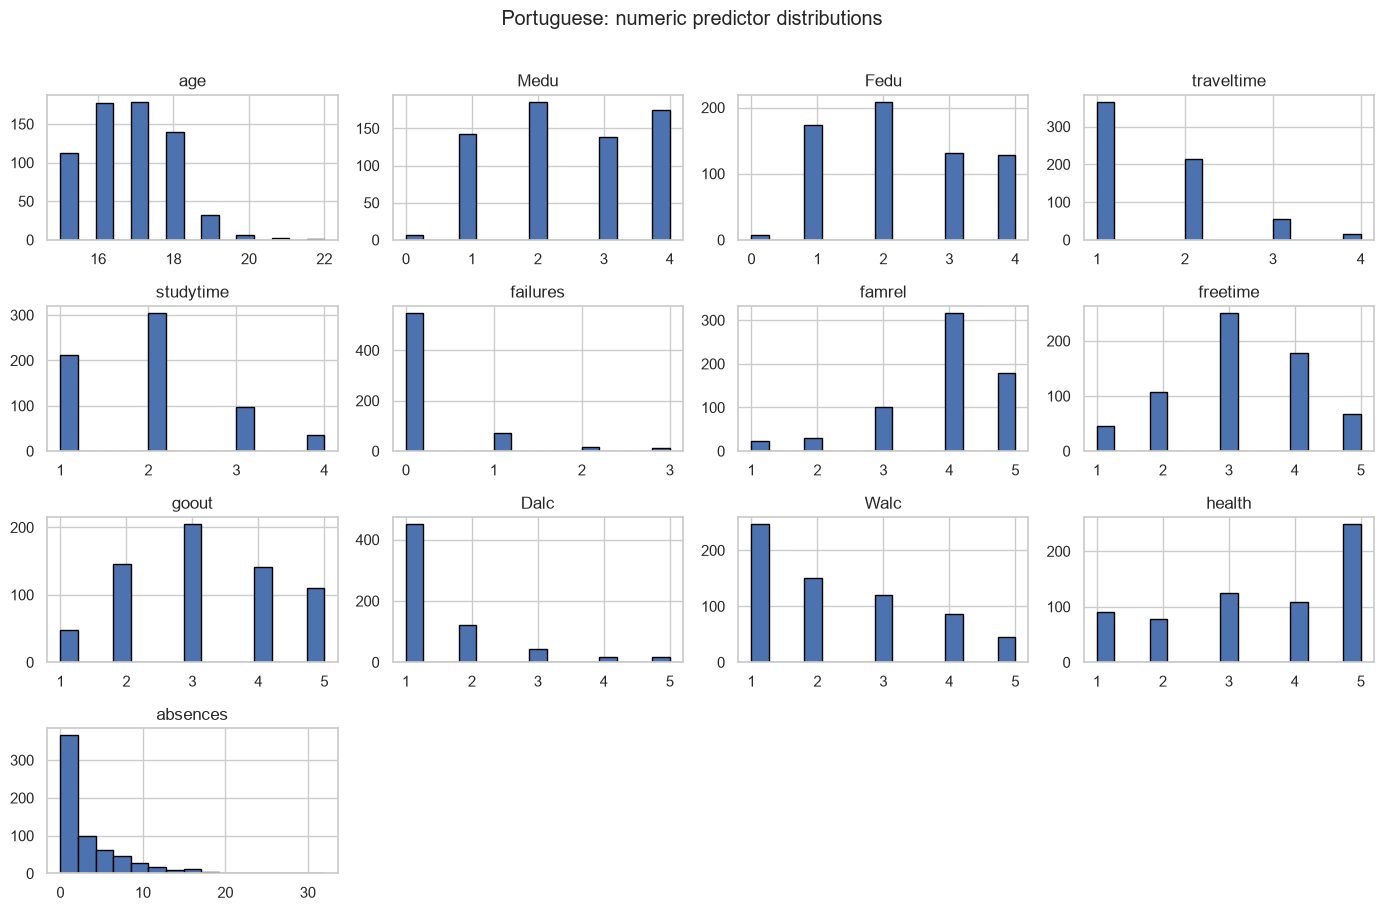

Observation guide: most numeric predictors are small ordinal scales. Absences is the clearly skewed one.


In [5]:
# Distributions of the numeric predictors (grades excluded because they are not model inputs)
for s in SUBJECTS:
    numeric_predictors = [c for c in raw[s].select_dtypes(include="number").columns if c not in EXCLUDED_FEATURES]
    raw[s][numeric_predictors].hist(figsize=(14, 9), bins=15, edgecolor="black", layout=(4, 4))
    plt.suptitle(f"{s}: numeric predictor distributions", y=1.01)
    plt.tight_layout()
    plt.show()
print("Observation guide: most numeric predictors are small ordinal scales. Absences is the clearly skewed one.")

Observation: Mathematics: strongest linear associations with risk: failures (+0.34), goout (+0.18), age (+0.18)
Observation: Portuguese: strongest linear associations with risk: failures (+0.38), studytime (-0.17), Fedu (-0.15)


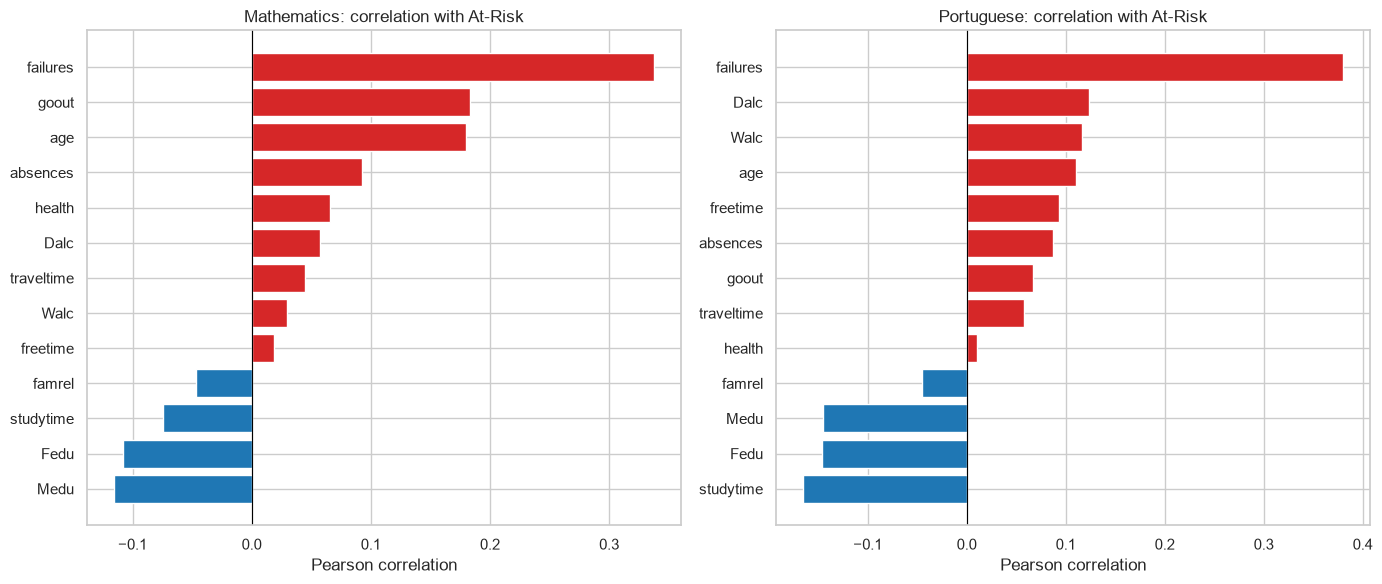

In [6]:
# Association of each numeric predictor with the At-Risk label (association, not causation)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, s in zip(axes, SUBJECTS):
    df = raw[s]
    risk = (df[TARGET_COLUMN] < RISK_THRESHOLD).astype(int)
    numeric_predictors = [c for c in df.select_dtypes(include="number").columns if c not in EXCLUDED_FEATURES]
    corr = df[numeric_predictors].corrwith(risk).sort_values()
    ax.barh(corr.index, corr.values, color=["tab:red" if v > 0 else "tab:blue" for v in corr.values])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{s}: correlation with At-Risk")
    ax.set_xlabel("Pearson correlation")
    top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(3)
    print(f"Observation: {s}: strongest linear associations with risk: "
          + ", ".join(f"{k} ({v:+.2f})" for k, v in top.items()))
plt.tight_layout()
plt.show()

Observation: Mathematics: predictor pairs with |correlation| >= 0.5: Medu/Fedu (+0.62), Dalc/Walc (+0.65)
Observation: Portuguese: predictor pairs with |correlation| >= 0.5: Medu/Fedu (+0.65), Dalc/Walc (+0.62)


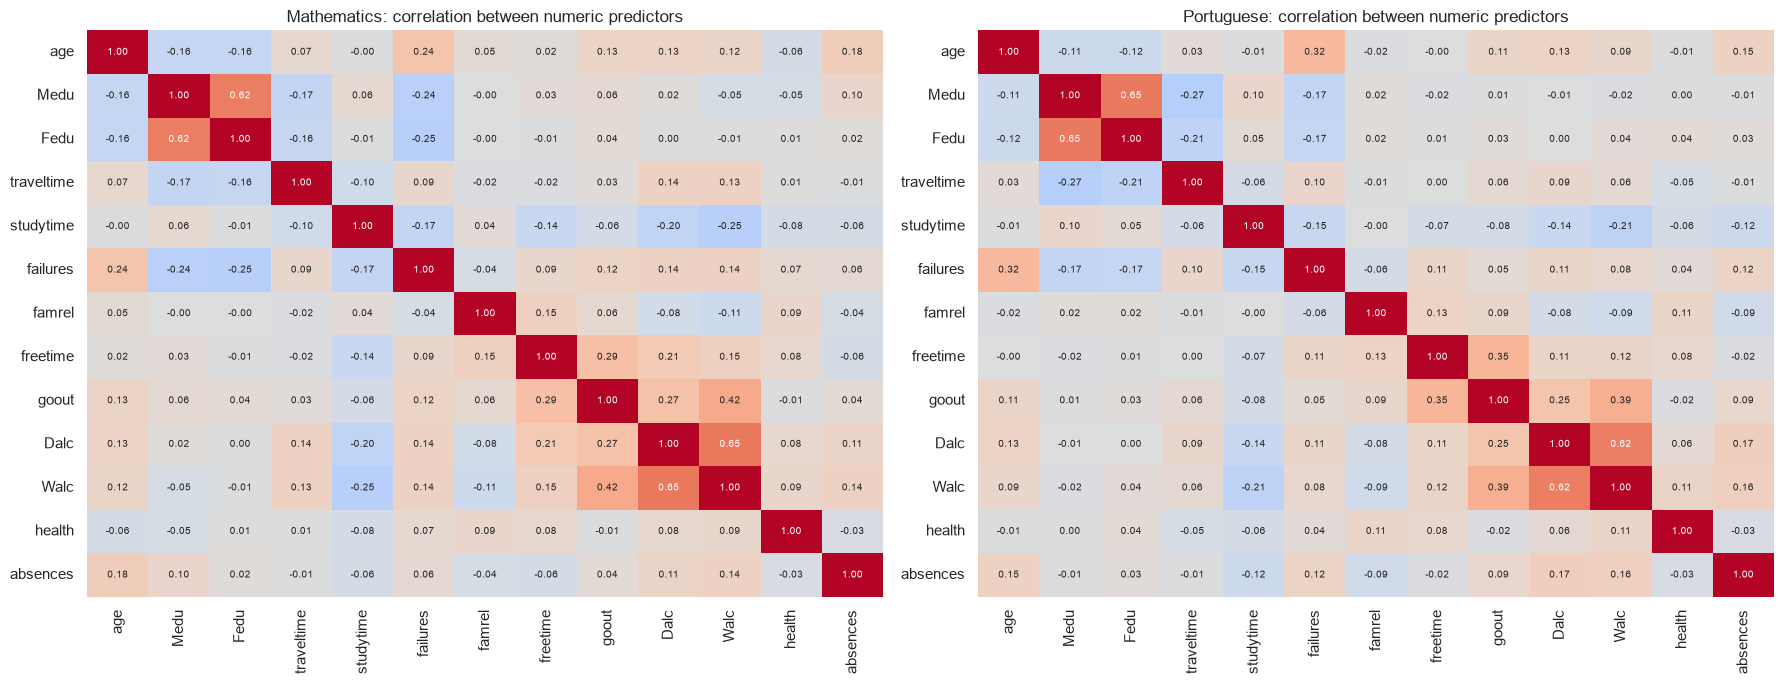

In [7]:
# Correlation between numeric predictors (strongly correlated inputs carry overlapping information)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, s in zip(axes, SUBJECTS):
    numeric_predictors = [c for c in raw[s].select_dtypes(include="number").columns if c not in EXCLUDED_FEATURES]
    corr = raw[s][numeric_predictors].corr()
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax, cbar=False)
    ax.set_title(f"{s}: correlation between numeric predictors")
    pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) >= 0.5]
    print(f"Observation: {s}: predictor pairs with |correlation| >= 0.5: "
          + (", ".join(f"{a}/{b} ({v:+.2f})" for a, b, v in pairs) if pairs else "none"))
plt.tight_layout()
plt.show()

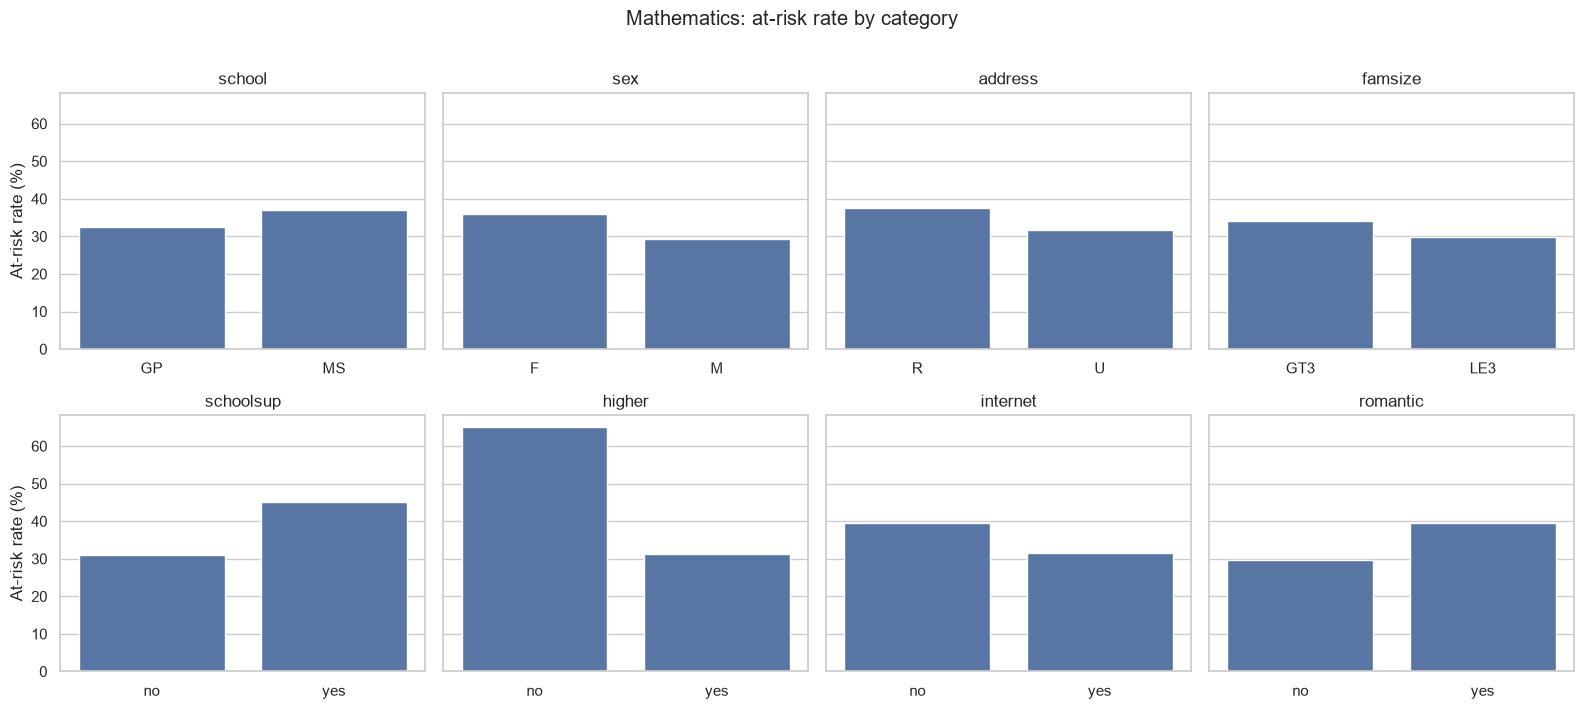

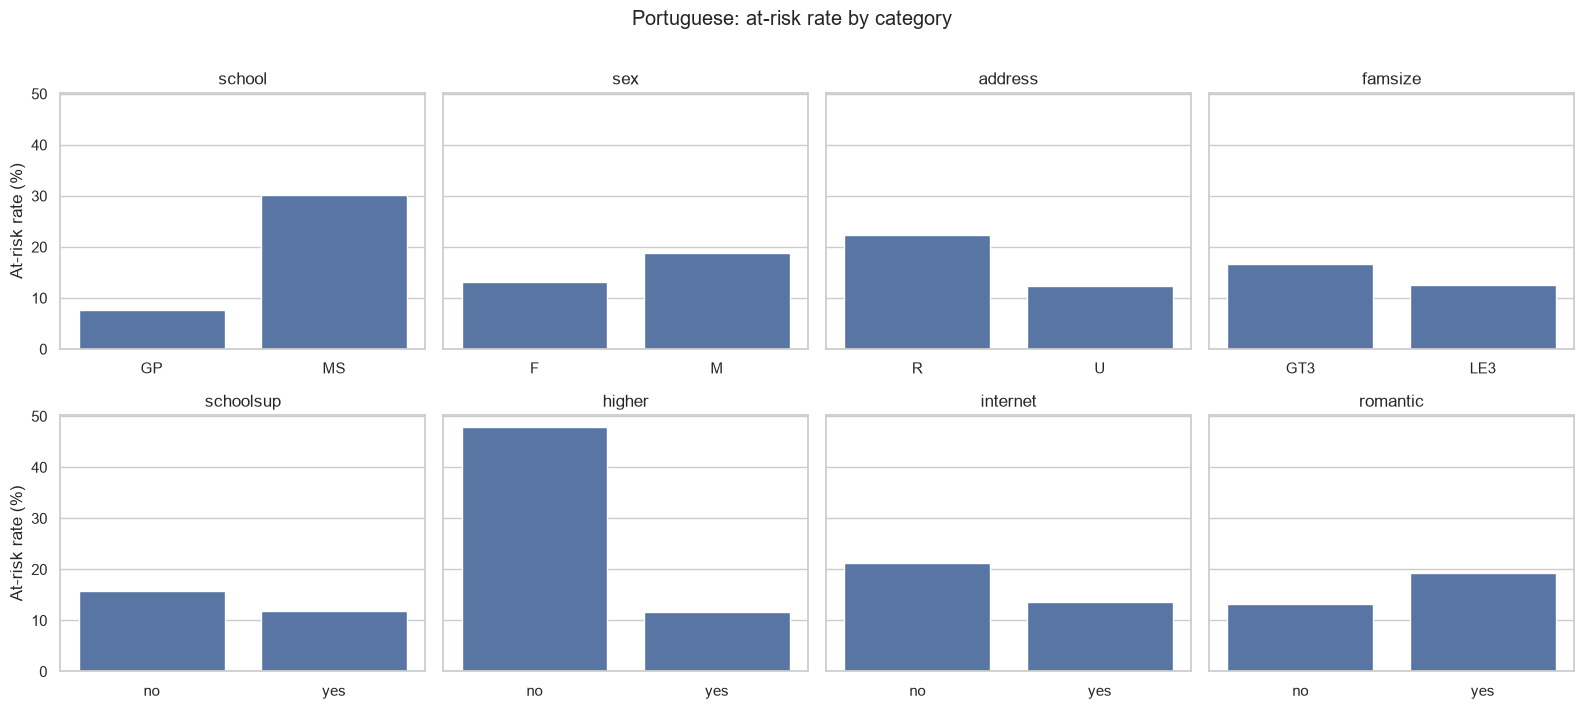

Observation guide: a large gap between categories means the groups differ in risk. It does not show why.


In [8]:
# At-risk rate by category for eight categorical predictors
cat_cols = ["school", "sex", "address", "famsize", "schoolsup", "higher", "internet", "romantic"]
for s in SUBJECTS:
    df = raw[s].copy()
    df["at_risk"] = (df[TARGET_COLUMN] < RISK_THRESHOLD).astype(int)
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
    for ax, name in zip(axes.flat, cat_cols):
        rate = df.groupby(name)["at_risk"].mean().mul(100)
        sns.barplot(x=rate.index, y=rate.values, ax=ax)
        ax.set_title(name)
        ax.set_xlabel("")
        ax.set_ylabel("At-risk rate (%)")
    fig.suptitle(f"{s}: at-risk rate by category", y=1.01)
    plt.tight_layout()
    plt.show()
print("Observation guide: a large gap between categories means the groups differ in risk. It does not show why.")

## Step 3: Target definition and feature preparation

- **What are we doing?** Creating the binary target and removing `G1`, `G2` and `G3` from the predictors.
- **Why?** `G3` defines the label, and `G1` and `G2` are earlier grades in the same course. Using them would let the model infer risk from grades, which defeats early identification. All other columns stay as predictors.
- **What does the code produce?** One `prepare_features` function, the feature and target counts, leakage checks, and the numeric and categorical column lists.
- **How to interpret it?** Both leakage checks must print `True`. The predictor count should be the original column count minus three.
- **What happens next?** Step 4 splits the data and defines the preprocessing pipeline.

In [9]:
def prepare_features(df):
    """Return predictors X and the At-Risk target y (1 = G3 below the cut-off)."""
    y = (df[TARGET_COLUMN] < RISK_THRESHOLD).astype(int)
    X = df.drop(columns=EXCLUDED_FEATURES).copy()    # leakage control: no grade columns
    return X, y

features, target = {}, {}
for s in SUBJECTS:
    features[s], target[s] = prepare_features(raw[s])

feature_summary = pd.DataFrame({
    s: {
        "Predictor columns": features[s].shape[1],
        "Numeric predictors": features[s].select_dtypes(include="number").shape[1],
        "Categorical predictors": features[s].select_dtypes(exclude="number").shape[1],
        "At-Risk students": int(target[s].sum()),
        "Not-At-Risk students": int((1 - target[s]).sum()),
        "Grade columns excluded from inputs": all(c not in features[s].columns for c in EXCLUDED_FEATURES),
        "Target values": str([int(v) for v in sorted(target[s].unique())]),
    }
    for s in SUBJECTS
})
display(feature_summary)

print("Numeric predictors:", features["Mathematics"].select_dtypes(include="number").columns.tolist())
print("\nCategorical predictors:", features["Mathematics"].select_dtypes(exclude="number").columns.tolist())

,Mathematics,Portuguese
Predictor columns,30,30
Numeric predictors,13,13
Categorical predictors,17,17
At-Risk students,130,100
Not-At-Risk students,265,549
Grade columns excluded from inputs,True,True
Target values,"[0, 1]","[0, 1]"


Numeric predictors: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Categorical predictors: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


## Step 4: Train-test split and preprocessing

- **What are we doing?** Splitting each subject into 80% training and 20% test data (stratified), and defining one preprocessing-plus-model pipeline.
- **Why?** Stratification keeps the At-Risk share similar in both parts. SVM works with distances and margins, so numeric inputs are standardised (otherwise a wide-range input such as absences would dominate). Categorical columns get most-frequent imputation and one-hot encoding. Putting this inside the `Pipeline` means it is learned from training data only, and refitted inside each CV fold during tuning, so the test set never influences it.
- **What does the code produce?** A `data` dictionary with each subject's split, a split summary, the `build_svm_pipeline` function, and evaluation and plotting helpers.
- **How to interpret it?** Training and test At-Risk percentages should be almost equal.
- **What happens next?** Step 5 trains the baseline on the training data and scores it once on the test data.

In [10]:
# Stratified split, identical for the baseline and the tuned model
data = {}
for s in SUBJECTS:
    X_train, X_test, y_train, y_test = train_test_split(
        features[s], target[s],
        test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=target[s],
    )
    data[s] = {"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test}

split_summary = pd.DataFrame({
    s: {
        "Training records": len(d["X_train"]),
        "Test records": len(d["X_test"]),
        "Training At-Risk (%)": round(d["y_train"].mean() * 100, 2),
        "Test At-Risk (%)": round(d["y_test"].mean() * 100, 2),
        "Test At-Risk students": int(d["y_test"].sum()),
    }
    for s, d in data.items()
})
display(split_summary)

,Mathematics,Portuguese
Training records,316.00,519.00
Test records,79.00,130.00
Training At-Risk (%),32.91,15.41
Test At-Risk (%),32.91,15.38
Test At-Risk students,26.00,20.00


In [11]:
# Baseline settings from the original notebook (these are also scikit-learn's defaults for SVC)
BASELINE_PARAMS = {"kernel": "rbf", "C": 1.0, "class_weight": None}


def build_svm_pipeline(X_train, **svc_params):
    """Preprocessing + SVC. Unfitted: every fit learns only from the data it is given."""
    numeric = X_train.select_dtypes(include="number").columns.tolist()
    categorical = X_train.select_dtypes(exclude="number").columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),                  # SVM is distance based, so inputs need a common scale
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric),
        ("categorical", categorical_pipeline, categorical),
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        # probability=True is needed for ROC-AUC and precision-recall curves
        ("classifier", SVC(probability=True, random_state=RANDOM_STATE, **svc_params)),
    ])


def evaluate_model(model, X_test, y_test):
    """Score a fitted model on the held-out test set with the same definitions every time."""
    assert list(model.named_steps["classifier"].classes_) == [0, 1]   # column 1 of predict_proba is At-Risk
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "At-Risk Precision": precision_score(y_test, y_pred, zero_division=0),
        "At-Risk Recall": recall_score(y_test, y_pred, zero_division=0),
        "At-Risk F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(y_test, y_prob),
    }
    return {"metrics": metrics, "y_pred": y_pred, "y_prob": y_prob}


def plot_confusion_matrices(evaluations, title, cmap):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, s in zip(axes, SUBJECTS):
        cm = confusion_matrix(data[s]["y_test"], evaluations[s]["y_pred"], labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
        ax.set_title(f"{s}: {title}")
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Actual class")
    plt.tight_layout()
    plt.show()


def plot_roc_and_pr(evaluations, title):
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    for i, s in enumerate(SUBJECTS):
        y_test, prob = data[s]["y_test"], evaluations[s]["y_prob"]
        RocCurveDisplay.from_predictions(y_test, prob, name=s, ax=axes[i])
        axes[i].plot([0, 1], [0, 1], linestyle="--", linewidth=1)
        axes[i].set_title(f"{s}: {title} ROC curve")
        PrecisionRecallDisplay.from_predictions(y_test, prob, name=s, ax=axes[2 + i])
        axes[2 + i].set_title(f"{s}: {title} precision-recall curve")
    plt.tight_layout()
    plt.show()


def describe_confusion(evaluations, label):
    """Plain-language reading of each confusion matrix, computed from the results."""
    for s in SUBJECTS:
        tn, fp, fn, tp = confusion_matrix(data[s]["y_test"], evaluations[s]["y_pred"], labels=[0, 1]).ravel()
        print(f"{label} {s}: detected {tp} of {tp + fn} at-risk students (recall {tp / (tp + fn):.0%}); "
              f"missed {fn}; flagged {fp} not-at-risk students unnecessarily.")
        if tp + fp == 0:
            print(f"  Note: this model flagged no students at all, so its precision is reported as 0 by convention.")

print("Pipeline and evaluation helpers defined.")

Pipeline and evaluation helpers defined.


## Step 5: Baseline SVM model (before tuning)

- **What are we doing?** Training the original baseline: `SVC(kernel="rbf", C=1.0, class_weight=None, probability=True, random_state=42)`.
- **Why?** Without a baseline we cannot tell whether tuning helps. An SVM looks for the boundary that separates the two classes with the widest possible **margin**. The training points closest to that boundary are the **support vectors**, and only they define it.
  - `kernel`: the shape of the boundary. `linear` gives a flat boundary. `rbf` gives a flexible, curved one.
  - `C`: the trade-off between a wide margin and training mistakes. A small `C` tolerates more mistakes and gives a smoother boundary. A large `C` punishes mistakes more and can overfit.
  - `gamma` (rbf only): how far one point's influence reaches. It stays at the default `"scale"` and is **not tuned**, so no `gamma` value is reported as a selected setting.
  - `class_weight`: with `"balanced"`, mistakes on the rarer At-Risk class cost more.
- **What does the code produce?** A fitted baseline model per subject, a metrics table, confusion matrices, ROC and precision-recall curves.
- **How to interpret it?** Precision is the share of flagged students who are truly at risk. Recall is the share of truly at-risk students found. F1 balances the two. ROC-AUC measures how well probabilities rank students. A **false negative** is a missed at-risk student, which is the costly error for early support.
- **A note on probabilities:** `SVC.predict` uses the sign of the SVM decision function. `predict_proba` is a separate probability estimate fitted by an internal 5-fold calibration, and ROC-AUC and the curves use it. The two can disagree slightly, so a student can be predicted At-Risk with a probability below 0.5.
- **What happens next?** Step 6 searches for better settings using training data only.

In [12]:
# Fit on training data only, then score once on the held-out test set
baseline_models, baseline_eval = {}, {}
for s in SUBJECTS:
    model = build_svm_pipeline(data[s]["X_train"], **BASELINE_PARAMS)
    model.fit(data[s]["X_train"], data[s]["y_train"])
    baseline_models[s] = model
    baseline_eval[s] = evaluate_model(model, data[s]["X_test"], data[s]["y_test"])

    print(f"\n{'=' * 50}\n{s}: baseline classification report (test set)\n{'=' * 50}")
    print(classification_report(data[s]["y_test"], baseline_eval[s]["y_pred"],
                                target_names=CLASS_NAMES, zero_division=0))

baseline_df = pd.DataFrame([{"Dataset": s, **baseline_eval[s]["metrics"]} for s in SUBJECTS])
print("Baseline test metrics")
display(baseline_df.round(4))

c:\Users\USER\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Mathematics: baseline classification report (test set)
              precision    recall  f1-score   support

 Not-At-Risk       0.71      0.94      0.81        53
     At-Risk       0.67      0.23      0.34        26

    accuracy                           0.71        79
   macro avg       0.69      0.59      0.58        79
weighted avg       0.70      0.71      0.66        79



c:\Users\USER\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Portuguese: baseline classification report (test set)
              precision    recall  f1-score   support

 Not-At-Risk       0.84      0.98      0.91       110
     At-Risk       0.00      0.00      0.00        20

    accuracy                           0.83       130
   macro avg       0.42      0.49      0.45       130
weighted avg       0.71      0.83      0.77       130

Baseline test metrics


,Dataset,Accuracy,At-Risk Precision,At-Risk Recall,At-Risk F1,ROC-AUC,Average Precision
0,Mathematics,0.7089,0.6667,0.2308,0.3429,0.6865,0.5733
1,Portuguese,0.8308,0.0000,0.0000,0.0000,0.8091,0.3616


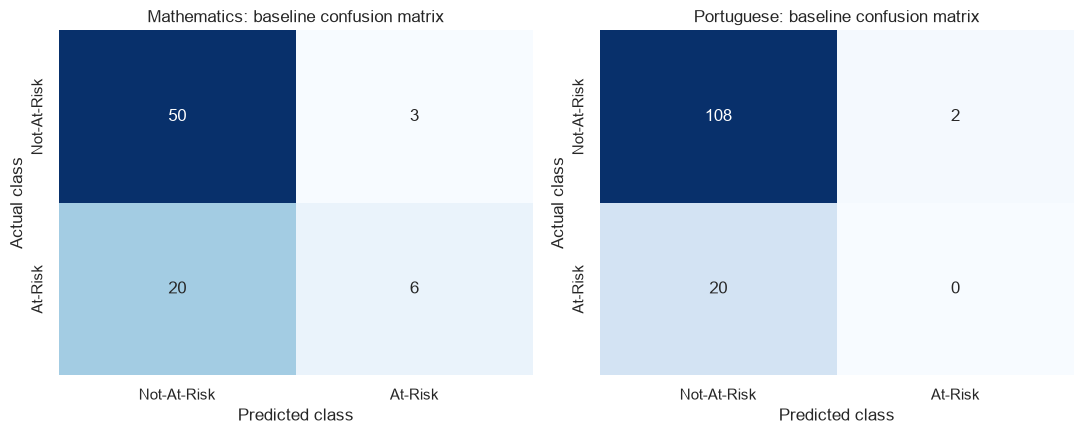

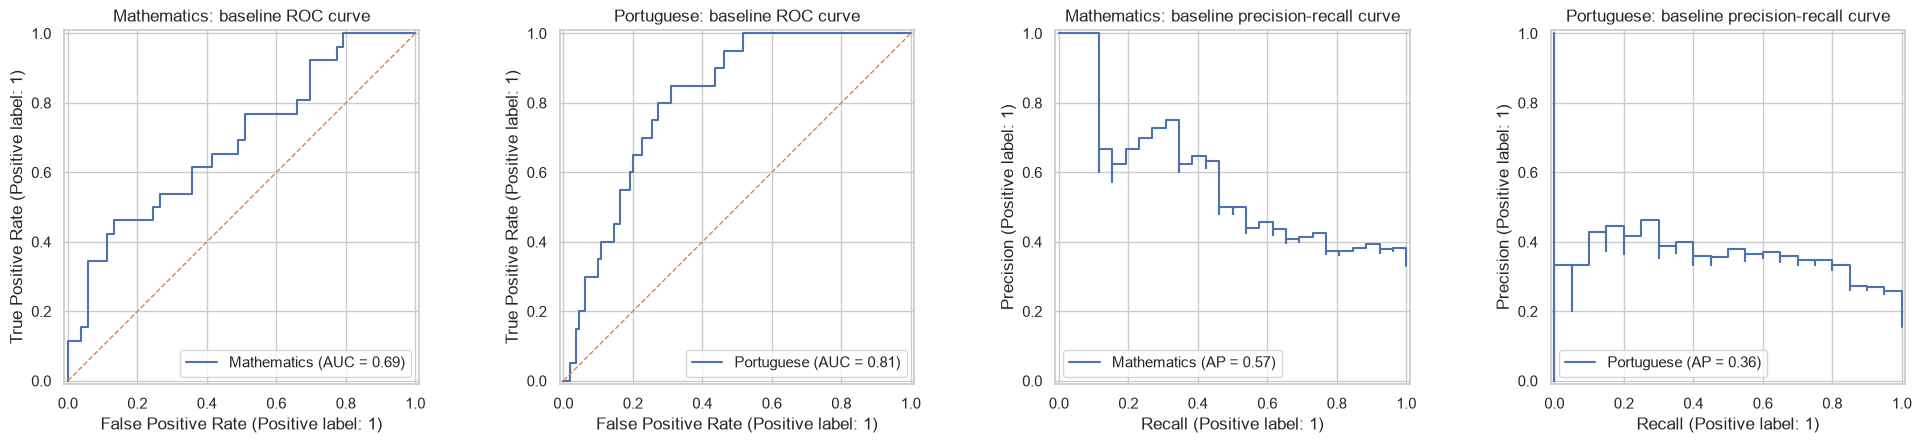

Baseline Mathematics: detected 6 of 26 at-risk students (recall 23%); missed 20; flagged 3 not-at-risk students unnecessarily.
Baseline Portuguese: detected 0 of 20 at-risk students (recall 0%); missed 20; flagged 2 not-at-risk students unnecessarily.


In [13]:
plot_confusion_matrices(baseline_eval, "baseline confusion matrix", "Blues")
plot_roc_and_pr(baseline_eval, "baseline")
describe_confusion(baseline_eval, "Baseline")

## Step 6: Hyperparameter tuning

- **What are we doing?** Running `GridSearchCV` over 12 combinations of three hyperparameters, using 5-fold stratified cross-validation on the **training data only**. The score used to choose is **F1 for the At-Risk class**.
- **Which parameters?**
  - `kernel` (`linear`, `rbf`): a linear boundary is simpler and less likely to overfit. An rbf boundary can follow curved patterns but can also overfit a small dataset.
  - `C` (0.1, 1, 10): the margin versus mistakes trade-off described in Step 5.
  - `class_weight` (`None`, `"balanced"`): `"balanced"` usually raises recall and lowers precision.
  - `gamma` is not tuned and stays at its default.
- **Why F1?** It rewards finding at-risk students without flagging too many others. The test set is not used in this step.
- **What does the code produce?** The best parameters, the best mean CV F1, the top configurations, a chart of all 12 configurations, and the CV F1 of the baseline settings on the same folds.
- **How to interpret it?** CV F1 values come from training folds and are not test results. The baseline settings (`rbf`, `C=1`, no class weight) are part of the grid, so the best CV F1 can never be below the baseline's CV F1. If the best `C` sits at an edge of the grid, a value beyond the edge was never tested.
- **What happens next?** Step 7 evaluates the selected model on the same test set used for the baseline.

In [14]:
cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

param_grid = {
    "classifier__kernel": ["linear", "rbf"],
    "classifier__C": [0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"],
}

grids, tuning_rows, cv_tables = {}, [], {}
for s in SUBJECTS:
    X_train, y_train = data[s]["X_train"], data[s]["y_train"]

    grid = GridSearchCV(build_svm_pipeline(X_train), param_grid,
                        scoring="f1", cv=cv, n_jobs=1, refit=True, error_score="raise")
    grid.fit(X_train, y_train)          # training data only
    grids[s] = grid

    # Baseline settings scored on the same folds, so the two CV F1 values are comparable
    baseline_cv_f1 = cross_val_score(build_svm_pipeline(X_train, **BASELINE_PARAMS), X_train, y_train,
                                     cv=cv, scoring="f1").mean()
    tuning_rows.append({
        "Dataset": s,
        "Best Kernel": grid.best_params_["classifier__kernel"],
        "Best C": grid.best_params_["classifier__C"],
        "Class Weight": grid.best_params_["classifier__class_weight"],
        "Best CV F1": grid.best_score_,
        "Baseline CV F1 (rbf, C=1, no class weight)": baseline_cv_f1,
    })

    res = pd.DataFrame(grid.cv_results_)
    cv_tables[s] = pd.DataFrame({
        "Rank": res["rank_test_score"],
        # read values from the params dicts: the param_* columns turn None into NaN in recent pandas
        "Kernel": res["params"].apply(lambda p: p["classifier__kernel"]),
        "C": res["params"].apply(lambda p: p["classifier__C"]),
        "Class weight": res["params"].apply(lambda p: str(p["classifier__class_weight"])),
        "Mean CV F1": res["mean_test_score"],
        "Std CV F1": res["std_test_score"],
    }).sort_values(["Rank", "Kernel", "C"]).reset_index(drop=True)

tuning_df = pd.DataFrame(tuning_rows)
display(tuning_df.round(4))

for s in SUBJECTS:
    print(f"\n{s}: top 5 configurations by mean CV F1")
    display(cv_tables[s].head(5).round(4))

c:\Users\USER\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\USER\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\USER\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\USER\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_bas

,Dataset,Best Kernel,Best C,Class Weight,Best CV F1,"Baseline CV F1 (rbf, C=1, no class weight)"
0,Mathematics,linear,10.0,balanced,0.481,0.3158
1,Portuguese,rbf,0.1,balanced,0.496,0.2826



Mathematics: top 5 configurations by mean CV F1


,Rank,Kernel,C,Class weight,Mean CV F1,Std CV F1
0,1,linear,10.0,balanced,0.4810,0.0476
1,2,linear,0.1,balanced,0.4777,0.0242
2,3,rbf,1.0,balanced,0.4667,0.0557
3,4,linear,1.0,balanced,0.4571,0.0482
4,5,rbf,0.1,balanced,0.4190,0.1396



Portuguese: top 5 configurations by mean CV F1


,Rank,Kernel,C,Class weight,Mean CV F1,Std CV F1
0,1,rbf,0.1,balanced,0.4960,0.0771
1,2,linear,0.1,balanced,0.4644,0.0701
2,3,linear,10.0,balanced,0.4407,0.0533
3,4,rbf,1.0,balanced,0.4403,0.1291
4,5,linear,1.0,balanced,0.4316,0.0540


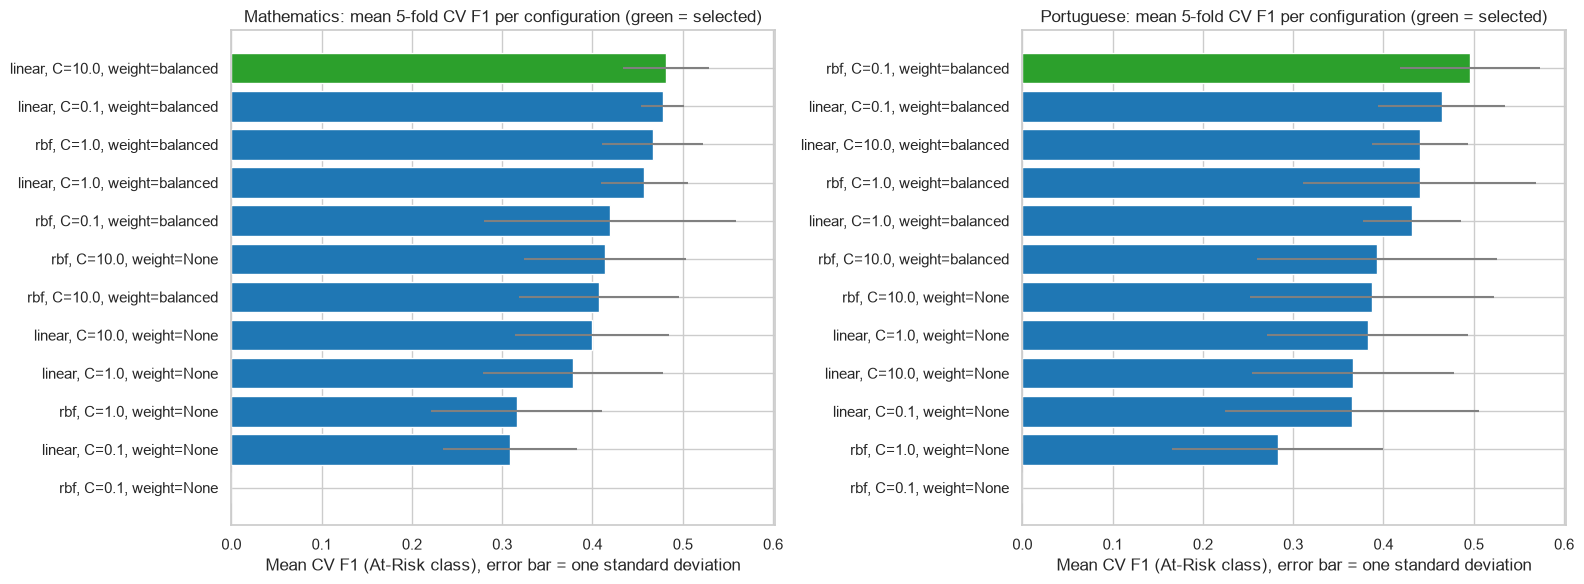

Observation: Mathematics: best CV F1 0.4810 versus 0.3158 for the baseline settings (difference +0.1652). Selected kernel=linear, C=10.0, class_weight=balanced.
  The selected C=10.0 is at the edge of the grid, so a more extreme value was not tested.
  Average CV F1 by class weight: {'None': 0.3027, 'balanced': 0.4515}; by kernel: {'linear': 0.4171, 'rbf': 0.3371}
  The gap between the first and second configuration is smaller than the fold-to-fold spread, so the choice between them is not strongly determined by the data.
Observation: Portuguese: best CV F1 0.4960 versus 0.2826 for the baseline settings (difference +0.2133). Selected kernel=rbf, C=0.1, class_weight=balanced.
  The selected C=0.1 is at the edge of the grid, so a more extreme value was not tested.
  Average CV F1 by class weight: {'None': 0.2973, 'balanced': 0.4443}; by kernel: {'linear': 0.4084, 'rbf': 0.3332}
  The gap between the first and second configuration is smaller than the fold-to-fold spread, so the choice bet

In [15]:
# All 12 tested configurations: what the search actually looked at
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
for ax, s in zip(axes, SUBJECTS):
    t = cv_tables[s].copy()
    t["Configuration"] = t.apply(lambda r: f"{r['Kernel']}, C={r['C']}, weight={r['Class weight']}", axis=1)
    t = t.sort_values("Mean CV F1")
    colors = ["tab:green" if r == 1 else "tab:blue" for r in t["Rank"]]
    ax.barh(t["Configuration"], t["Mean CV F1"], xerr=t["Std CV F1"], color=colors, ecolor="gray")
    ax.set_title(f"{s}: mean 5-fold CV F1 per configuration (green = selected)")
    ax.set_xlabel("Mean CV F1 (At-Risk class), error bar = one standard deviation")
plt.tight_layout()
plt.show()

c_values = param_grid["classifier__C"]
for s in SUBJECTS:
    row = tuning_df.set_index("Dataset").loc[s]
    base_col = "Baseline CV F1 (rbf, C=1, no class weight)"
    gain = row["Best CV F1"] - row[base_col]
    print(f"Observation: {s}: best CV F1 {row['Best CV F1']:.4f} versus {row[base_col]:.4f} for the baseline settings "
          f"(difference {gain:+.4f}). Selected kernel={row['Best Kernel']}, C={row['Best C']}, class_weight={row['Class Weight']}.")
    if row["Best C"] in (min(c_values), max(c_values)):
        print(f"  The selected C={row['Best C']} is at the edge of the grid, so a more extreme value was not tested.")
    t = cv_tables[s]
    by_weight = t.groupby("Class weight")["Mean CV F1"].mean().round(4).to_dict()
    by_kernel = t.groupby("Kernel")["Mean CV F1"].mean().round(4).to_dict()
    print(f"  Average CV F1 by class weight: {by_weight}; by kernel: {by_kernel}")
    top_std = t.iloc[0]["Std CV F1"]
    second = t.iloc[1]["Mean CV F1"]
    if t.iloc[0]["Mean CV F1"] - second < top_std:
        print("  The gap between the first and second configuration is smaller than the fold-to-fold spread, "
              "so the choice between them is not strongly determined by the data.")

## Step 7: Evaluate the tuned model

- **What are we doing?** Taking the best pipeline from each grid search (already refitted on the full training set) and scoring it on the held-out test set.
- **Why?** The test set has been used for nothing except the baseline score, so it is a fair and identical yardstick for both models. The metric function is the same one used in Step 5.
- **What does the code produce?** Tuned test metrics, classification reports, confusion matrices, ROC and precision-recall curves.
- **How to interpret it?** These are test results. Do not compare them with the CV F1 values from Step 6, which come from different data.
- **What happens next?** Step 8 places baseline and tuned results side by side.

In [16]:
tuned_models = {s: grids[s].best_estimator_ for s in SUBJECTS}
tuned_eval = {s: evaluate_model(tuned_models[s], data[s]["X_test"], data[s]["y_test"]) for s in SUBJECTS}

for s in SUBJECTS:
    print(f"\n{'=' * 50}\n{s}: tuned classification report (test set)\n{'=' * 50}")
    print(classification_report(data[s]["y_test"], tuned_eval[s]["y_pred"],
                                target_names=CLASS_NAMES, zero_division=0))

tuned_df = pd.DataFrame([{"Dataset": s, **tuned_eval[s]["metrics"]} for s in SUBJECTS])
print("Tuned test metrics")
display(tuned_df.round(4))


Mathematics: tuned classification report (test set)
              precision    recall  f1-score   support

 Not-At-Risk       0.81      0.72      0.76        53
     At-Risk       0.53      0.65      0.59        26

    accuracy                           0.70        79
   macro avg       0.67      0.69      0.67        79
weighted avg       0.72      0.70      0.70        79


Portuguese: tuned classification report (test set)
              precision    recall  f1-score   support

 Not-At-Risk       0.93      0.76      0.84       110
     At-Risk       0.35      0.70      0.47        20

    accuracy                           0.75       130
   macro avg       0.64      0.73      0.65       130
weighted avg       0.84      0.75      0.78       130

Tuned test metrics


,Dataset,Accuracy,At-Risk Precision,At-Risk Recall,At-Risk F1,ROC-AUC,Average Precision
0,Mathematics,0.6962,0.5312,0.6538,0.5862,0.7097,0.584
1,Portuguese,0.7538,0.3500,0.7000,0.4667,0.8123,0.372


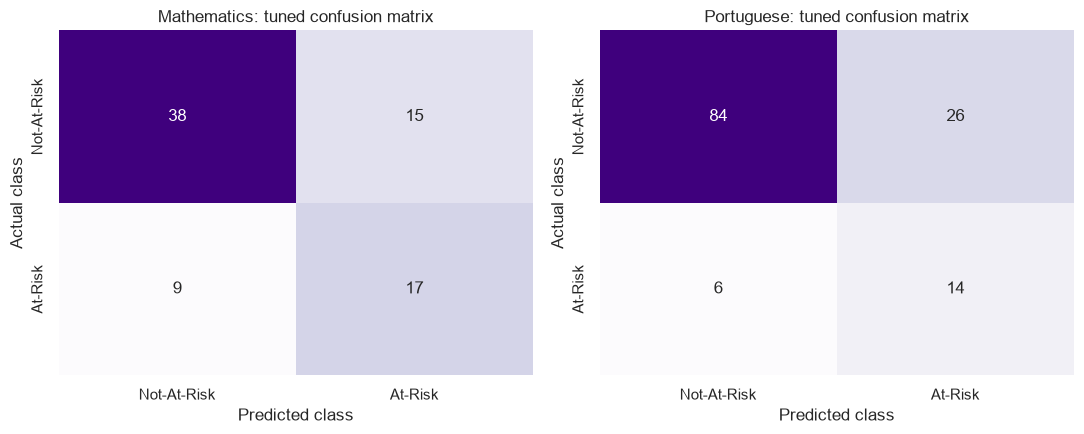

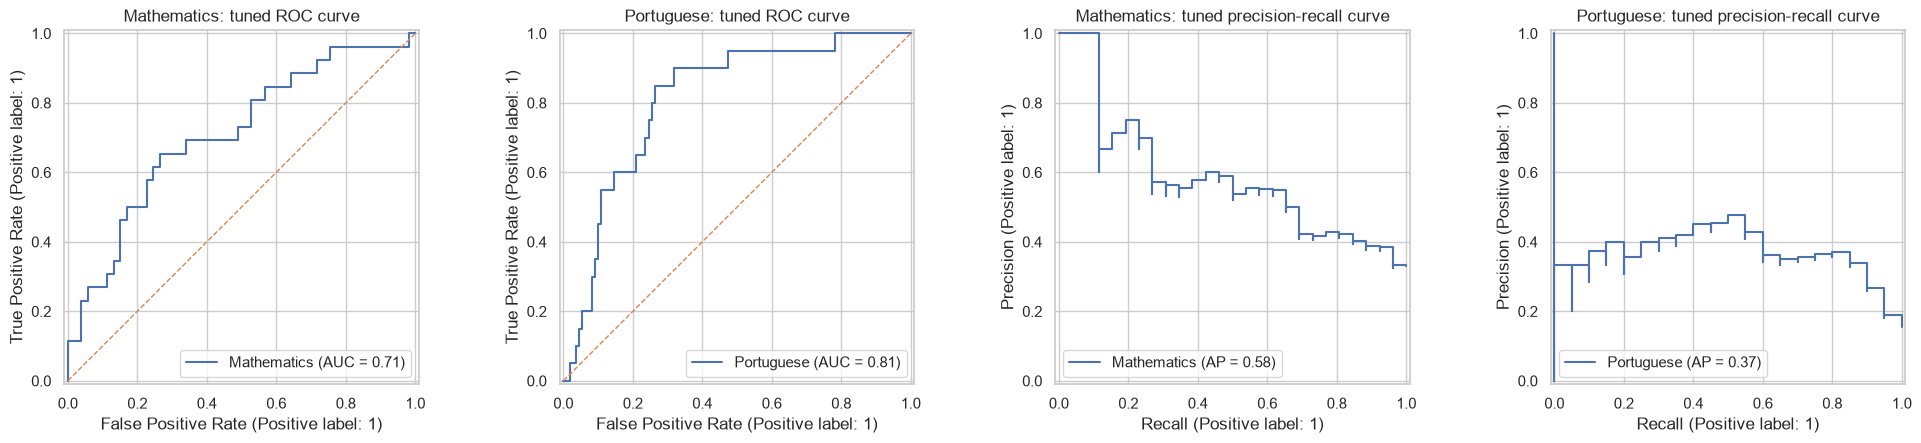

Tuned Mathematics: detected 17 of 26 at-risk students (recall 65%); missed 9; flagged 15 not-at-risk students unnecessarily.
Tuned Portuguese: detected 14 of 20 at-risk students (recall 70%); missed 6; flagged 26 not-at-risk students unnecessarily.


In [17]:
plot_confusion_matrices(tuned_eval, "tuned confusion matrix", "Purples")
plot_roc_and_pr(tuned_eval, "tuned")
describe_confusion(tuned_eval, "Tuned")

## Step 8: Compare baseline and tuned results

- **What are we doing?** Putting baseline and tuned test metrics side by side for each dataset.
- **Why?** Tuning is not guaranteed to help on unseen data. The comparison shows which metrics improved, which declined, and whether there is a trade-off such as higher recall at the cost of precision.
- **What does the code produce?** One table per dataset with the change in every metric, a grouped bar chart, and a computed summary.
- **How to interpret it?** Test sets are small, so one student changes recall by a visible amount. The summary prints how many at-risk students each test set holds.
- **What happens next?** Step 9 looks at what the fitted SVM models learned.


Mathematics: baseline versus tuned (held-out test set)


,Baseline,Tuned,Change (Tuned - Baseline)
Accuracy,0.7089,0.6962,-0.0127
At-Risk Precision,0.6667,0.5312,-0.1354
At-Risk Recall,0.2308,0.6538,0.4231
At-Risk F1,0.3429,0.5862,0.2433
ROC-AUC,0.6865,0.7097,0.0232



Portuguese: baseline versus tuned (held-out test set)


,Baseline,Tuned,Change (Tuned - Baseline)
Accuracy,0.8308,0.7538,-0.0769
At-Risk Precision,0.0000,0.3500,0.3500
At-Risk Recall,0.0000,0.7000,0.7000
At-Risk F1,0.0000,0.4667,0.4667
ROC-AUC,0.8091,0.8123,0.0032


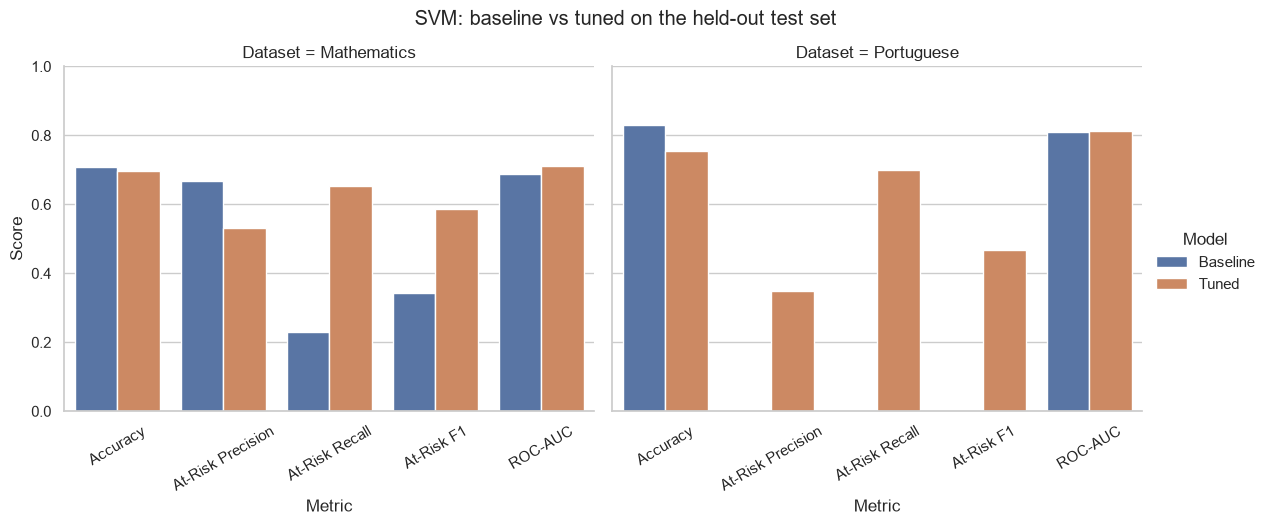

In [18]:
comparison_long = pd.concat([
    baseline_df.assign(Model="Baseline"),
    tuned_df.assign(Model="Tuned"),
], ignore_index=True)

comparison_tables = {}
for s in SUBJECTS:
    b = baseline_df.set_index("Dataset").loc[s, METRICS]
    t = tuned_df.set_index("Dataset").loc[s, METRICS]
    comparison_tables[s] = pd.DataFrame({"Baseline": b, "Tuned": t, "Change (Tuned - Baseline)": t - b})
    print(f"\n{s}: baseline versus tuned (held-out test set)")
    display(comparison_tables[s].round(4))

plot_df = comparison_long.melt(id_vars=["Dataset", "Model"], value_vars=METRICS,
                               var_name="Metric", value_name="Score")
g = sns.catplot(data=plot_df, kind="bar", x="Metric", y="Score", hue="Model",
                col="Dataset", height=4.5, aspect=1.3)
g.set(ylim=(0, 1))
g.set_xticklabels(rotation=30)
g.figure.suptitle("SVM: baseline vs tuned on the held-out test set", y=1.04)
plt.show()

In [19]:
TOL = 1e-9
for s in SUBJECTS:
    change = comparison_tables[s]["Change (Tuned - Baseline)"]
    improved = [m for m in METRICS if change[m] > TOL]
    declined = [m for m in METRICS if change[m] < -TOL]
    unchanged = [m for m in METRICS if abs(change[m]) <= TOL]
    n_pos = int(data[s]["y_test"].sum())
    row = tuning_df.set_index("Dataset").loc[s]

    print(f"\n{s} (tuned: kernel={row['Best Kernel']}, C={row['Best C']}, class_weight={row['Class Weight']})")
    print(f"  Improved: {', '.join(improved) if improved else 'none'}")
    print(f"  Declined: {', '.join(declined) if declined else 'none'}")
    print(f"  Unchanged: {', '.join(unchanged) if unchanged else 'none'}")
    if improved and declined:
        print("  Trade-off: tuning improved some metrics and worsened others, so the preferred model depends on "
              "whether missing at-risk students or over-flagging is the bigger concern.")
    elif not improved and declined:
        print("  Tuning did not improve any test metric for this dataset.")
    elif improved and not declined:
        print("  Tuning improved test metrics without a decline in any metric.")
    if row["Class Weight"] == "balanced" and change["At-Risk Recall"] > TOL and change["At-Risk Precision"] < -TOL:
        print("  Consistent with class_weight='balanced': recall rose while precision fell, because the model now "
              "flags more students as at risk.")
    print(f"  Caution: the test set contains {n_pos} at-risk students, so each one changes recall by {1 / n_pos:.1%}.")


Mathematics (tuned: kernel=linear, C=10.0, class_weight=balanced)
  Improved: At-Risk Recall, At-Risk F1, ROC-AUC
  Declined: Accuracy, At-Risk Precision
  Unchanged: none
  Trade-off: tuning improved some metrics and worsened others, so the preferred model depends on whether missing at-risk students or over-flagging is the bigger concern.
  Consistent with class_weight='balanced': recall rose while precision fell, because the model now flags more students as at risk.
  Caution: the test set contains 26 at-risk students, so each one changes recall by 3.8%.

Portuguese (tuned: kernel=rbf, C=0.1, class_weight=balanced)
  Improved: At-Risk Precision, At-Risk Recall, At-Risk F1, ROC-AUC
  Declined: Accuracy
  Unchanged: none
  Trade-off: tuning improved some metrics and worsened others, so the preferred model depends on whether missing at-risk students or over-flagging is the bigger concern.
  Caution: the test set contains 20 at-risk students, so each one changes recall by 5.0%.


## Step 9: What the SVM learned

- **What are we doing?** Looking at the fitted tuned models: how many support vectors each uses and, where the model is linear, which features push the decision toward At-Risk.
- **Why?** Unlike Logistic Regression, an SVM with an `rbf` kernel has no coefficients to read, so feature effects cannot be reported honestly for that kernel. A linear SVM does have a weight per feature.
- **What does the code produce?** A support-vector table, and for each subject whose selected kernel is `linear` a chart of the largest weights. For an `rbf` model the notebook states that no coefficients exist.
- **How to interpret it?**
  - Support vectors are the training students that define the boundary. A large share means the classes overlap heavily and the boundary depends on many students. They are not a ranking of features.
  - Linear weights are on the decision-function scale, not log-odds, so they are **not** odds ratios. A positive weight pushes a student toward At-Risk, a negative weight toward Not-At-Risk, holding other features fixed.
  - Numeric inputs are standardised (weight per standard deviation) and one-hot columns are 0 or 1, so sizes of the two kinds are not directly comparable. Weights are associations, not causes.
- **What happens next?** Step 10 collects everything into the final report.

,Dataset,Kernel,Support vectors (Not-At-Risk),Support vectors (At-Risk),Total support vectors,Training records,Share of training records (%)
0,Mathematics,linear,139,74,213,316,67.4
1,Portuguese,rbf,383,73,456,519,87.9


Portuguese: the selected kernel is 'rbf', so there are no feature weights to report for this model.


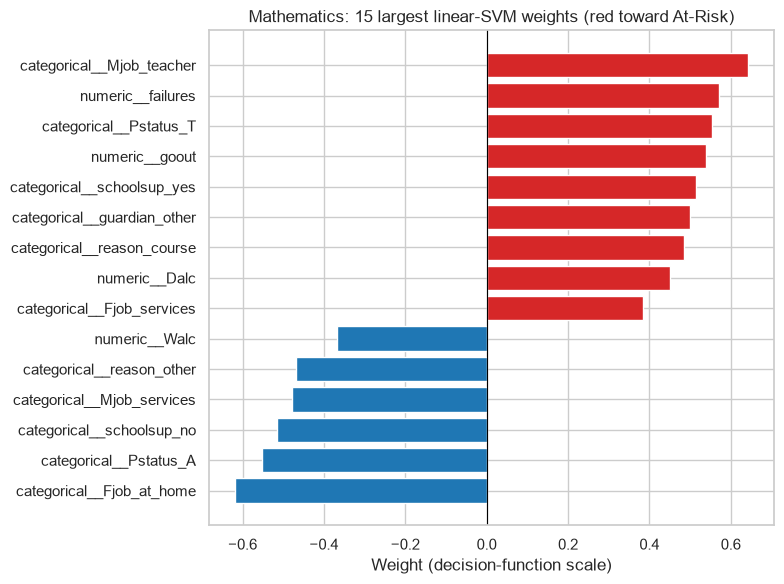

Mathematics: largest weights toward At-Risk: categorical__Mjob_teacher, numeric__failures, categorical__Pstatus_T; toward Not-At-Risk: categorical__Fjob_at_home, categorical__Pstatus_A, categorical__schoolsup_no
Reminder: weights describe how the fitted model separates the classes. They are not odds ratios or causal effects.


In [20]:
support_rows = []
for s in SUBJECTS:
    svc = tuned_models[s].named_steps["classifier"]
    n_train = len(data[s]["X_train"])
    support_rows.append({
        "Dataset": s,
        "Kernel": svc.kernel,
        "Support vectors (Not-At-Risk)": int(svc.n_support_[0]),
        "Support vectors (At-Risk)": int(svc.n_support_[1]),
        "Total support vectors": int(svc.n_support_.sum()),
        "Training records": n_train,
        "Share of training records (%)": round(svc.n_support_.sum() / n_train * 100, 1),
    })
display(pd.DataFrame(support_rows))


def linear_weight_table(model):
    """Feature weights of a linear SVM, with names taken from the fitted preprocessor."""
    svc = model.named_steps["classifier"]
    weights = svc.coef_.toarray()[0] if issparse(svc.coef_) else np.asarray(svc.coef_)[0]
    names = model.named_steps["preprocessor"].get_feature_names_out()
    table = pd.DataFrame({"Feature": names, "Weight": weights})
    table["Direction"] = np.where(table["Weight"] > 0, "toward At-Risk", "toward Not-At-Risk")
    table["Abs"] = table["Weight"].abs()
    return table.sort_values("Abs", ascending=False).drop(columns="Abs").reset_index(drop=True)


linear_subjects = [s for s in SUBJECTS if tuned_models[s].named_steps["classifier"].kernel == "linear"]
weight_tables = {s: linear_weight_table(tuned_models[s]) for s in linear_subjects}

for s in SUBJECTS:
    if s not in weight_tables:
        print(f"{s}: the selected kernel is '{tuned_models[s].named_steps['classifier'].kernel}', "
              "so there are no feature weights to report for this model.")

if weight_tables:
    fig, axes = plt.subplots(1, len(weight_tables), figsize=(8 * len(weight_tables), 6), squeeze=False)
    for ax, (s, table) in zip(axes[0], weight_tables.items()):
        top = table.head(15).sort_values("Weight")
        ax.barh(top["Feature"], top["Weight"], color=["tab:red" if v > 0 else "tab:blue" for v in top["Weight"]])
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_title(f"{s}: 15 largest linear-SVM weights (red toward At-Risk)")
        ax.set_xlabel("Weight (decision-function scale)")
    plt.tight_layout()
    plt.show()

    for s, table in weight_tables.items():
        up = table[table["Weight"] > 0].head(3)["Feature"].tolist()
        down = table[table["Weight"] < 0].head(3)["Feature"].tolist()
        print(f"{s}: largest weights toward At-Risk: {', '.join(up)}; toward Not-At-Risk: {', '.join(down)}")
    print("Reminder: weights describe how the fitted model separates the classes. They are not odds ratios or causal effects.")

## Step 10: Final results and recommendation

- **What are we doing?** Collecting baseline metrics, tuned metrics, best hyperparameters, the comparison and what the SVM learned into one report.
- **Why?** This is the section to read, present and copy into the group report. Every number comes from the cells above.
- **What does the code produce?** A summary per dataset and a computed interpretation.
- **How to interpret it?** Read each dataset block separately, because the subjects are modelled independently and have different class balance. Test metrics, CV F1 and training information are labelled separately.

In [21]:
for s in SUBJECTS:
    best = tuning_df.set_index("Dataset").loc[s]
    svc = tuned_models[s].named_steps["classifier"]
    print("=" * 72)
    print(f"{s.upper()}  |  SVM  |  held-out test set ({len(data[s]['y_test'])} students)")
    print("=" * 72)
    display(comparison_tables[s].round(4))
    print(f"Best hyperparameters: kernel={best['Best Kernel']}, C={best['Best C']}, class_weight={best['Class Weight']}")
    print(f"Mean CV F1 (training folds only): tuned {best['Best CV F1']:.4f}, "
          f"baseline settings {best['Baseline CV F1 (rbf, C=1, no class weight)']:.4f}")
    print(f"Support vectors in the tuned model: {int(svc.n_support_.sum())} of {len(data[s]['X_train'])} training students")
    if s in weight_tables:
        wt = weight_tables[s]
        print("Largest weights toward At-Risk:", ", ".join(wt[wt["Weight"] > 0].head(3)["Feature"]))
        print("Largest weights toward Not-At-Risk:", ", ".join(wt[wt["Weight"] < 0].head(3)["Feature"]))
    print()

MATHEMATICS  |  SVM  |  held-out test set (79 students)


,Baseline,Tuned,Change (Tuned - Baseline)
Accuracy,0.7089,0.6962,-0.0127
At-Risk Precision,0.6667,0.5312,-0.1354
At-Risk Recall,0.2308,0.6538,0.4231
At-Risk F1,0.3429,0.5862,0.2433
ROC-AUC,0.6865,0.7097,0.0232


Best hyperparameters: kernel=linear, C=10.0, class_weight=balanced
Mean CV F1 (training folds only): tuned 0.4810, baseline settings 0.3158
Support vectors in the tuned model: 213 of 316 training students
Largest weights toward At-Risk: categorical__Mjob_teacher, numeric__failures, categorical__Pstatus_T
Largest weights toward Not-At-Risk: categorical__Fjob_at_home, categorical__Pstatus_A, categorical__schoolsup_no

PORTUGUESE  |  SVM  |  held-out test set (130 students)


,Baseline,Tuned,Change (Tuned - Baseline)
Accuracy,0.8308,0.7538,-0.0769
At-Risk Precision,0.0000,0.3500,0.3500
At-Risk Recall,0.0000,0.7000,0.7000
At-Risk F1,0.0000,0.4667,0.4667
ROC-AUC,0.8091,0.8123,0.0032


Best hyperparameters: kernel=rbf, C=0.1, class_weight=balanced
Mean CV F1 (training folds only): tuned 0.4960, baseline settings 0.2826
Support vectors in the tuned model: 456 of 519 training students



In [22]:
print("COMPUTED INTERPRETATION (generated from this run's results)\n")
for s in SUBJECTS:
    b, t = baseline_eval[s]["metrics"], tuned_eval[s]["metrics"]

    def winner(metric):
        return "tuned" if t[metric] > b[metric] else "baseline" if b[metric] > t[metric] else "neither (tie)"

    print(f"{s}:")
    print(f"  Higher test F1: {winner('At-Risk F1')} (baseline {b['At-Risk F1']:.3f}, tuned {t['At-Risk F1']:.3f}).")
    print(f"  Higher test recall: {winner('At-Risk Recall')} (baseline {b['At-Risk Recall']:.3f}, tuned {t['At-Risk Recall']:.3f}).")
    print(f"  Higher test precision: {winner('At-Risk Precision')} (baseline {b['At-Risk Precision']:.3f}, tuned {t['At-Risk Precision']:.3f}).")
    print(f"  Higher test accuracy: {winner('Accuracy')} (baseline {b['Accuracy']:.3f}, tuned {t['Accuracy']:.3f}).")
    print(f"  ROC-AUC: baseline {b['ROC-AUC']:.3f}, tuned {t['ROC-AUC']:.3f}.")

    # Describe the model with the higher recall, since missing at-risk students is the costly error
    best_eval = tuned_eval[s] if t["At-Risk Recall"] >= b["At-Risk Recall"] else baseline_eval[s]
    tn, fp, fn, tp = confusion_matrix(data[s]["y_test"], best_eval["y_pred"], labels=[0, 1]).ravel()
    recall = tp / (tp + fn)
    if recall < 0.5:
        print(f"  Warning: even the better-recall model detects only {recall:.0%} of at-risk students, "
              "so it should not be the only screening tool.")
    else:
        print(f"  The better-recall model detects {recall:.0%} of at-risk students, at the cost of flagging "
              f"{fp} not-at-risk students.")
    print()

COMPUTED INTERPRETATION (generated from this run's results)

Mathematics:
  Higher test F1: tuned (baseline 0.343, tuned 0.586).
  Higher test recall: tuned (baseline 0.231, tuned 0.654).
  Higher test precision: baseline (baseline 0.667, tuned 0.531).
  Higher test accuracy: baseline (baseline 0.709, tuned 0.696).
  ROC-AUC: baseline 0.687, tuned 0.710.
  The better-recall model detects 65% of at-risk students, at the cost of flagging 15 not-at-risk students.

Portuguese:
  Higher test F1: tuned (baseline 0.000, tuned 0.467).
  Higher test recall: tuned (baseline 0.000, tuned 0.700).
  Higher test precision: tuned (baseline 0.000, tuned 0.350).
  Higher test accuracy: baseline (baseline 0.831, tuned 0.754).
  ROC-AUC: baseline 0.809, tuned 0.812.
  The better-recall model detects 70% of at-risk students, at the cost of flagging 26 not-at-risk students.



### Strengths, limitations and responsible use

**Strengths**
- SVM can model both linear and curved boundaries and works well with the standardised inputs in this pipeline.
- Preprocessing is fitted on training data only, the split is stratified and reproducible, and tuning never sees the test set.
- Evaluation reports precision, recall, F1 and ROC-AUC for the At-Risk class, not only accuracy.

**Limitations**
- An `rbf` SVM is hard to explain to educators, because it has no per-feature coefficients. A linear SVM is easier to read but cannot capture curved patterns.
- One-hot encoding produces many input columns for a small dataset, and the datasets hold few at-risk students, so metrics are noisy and sensitive to a handful of predictions. A single split does not show how much results vary.
- Probabilities from `SVC(probability=True)` are a calibrated estimate, not a guarantee, and can disagree slightly with the class prediction.
- The decision rule is the SVM's own boundary. `class_weight` shifts the recall and precision trade-off, but a threshold chosen on validation data may do better. Do not choose a threshold on the test set.
- The data come from two Portuguese secondary schools, so results may not transfer to other schools or cohorts. Several inputs describe family background and personal circumstances, and predictions based on them can reflect existing inequalities.

**Responsible use**
- Treat a prediction as a prompt for a supportive conversation, not as a label or a decision about a student.
- Validate on local data before real use, and check errors for groups that may be treated unfairly.
- The computed interpretation above is the evidence to cite in the assignment report. Check it against the tables before copying it.

## Step 11: Optional comparison with tuned Logistic Regression

- **What are we doing?** Scoring the saved tuned Logistic Regression models (from the Logistic Regression notebook) on this notebook's held-out test set, next to the tuned SVM.
- **Why?** The original notebook compared the two models. The comparison only means something if both used the same split. Both notebooks use the same seed, test size and stratification, so the test sets are identical.
- **What does the code produce?** A comparison table, or a message if the saved Logistic Regression models are not available.
- **How to interpret it?** The Logistic Regression files are produced by another notebook. If they are missing, this step is skipped and nothing is invented.

In [23]:
comparison_df = None
lr_paths = {s: MODEL_DIR / f"logistic_regression_{s.lower()}_tuned.joblib" for s in SUBJECTS}
missing_lr = [p.name for p in lr_paths.values() if not p.exists()]

if missing_lr:
    print("Skipped: saved Logistic Regression model file(s) not found in", MODEL_DIR.resolve())
    print("Missing:", ", ".join(missing_lr))
    print("Run the Logistic Regression notebook first if you want this comparison.")
else:
    rows = []
    for s in SUBJECTS:
        lr_model = joblib.load(lr_paths[s])
        for name, model in [("Tuned Logistic Regression", lr_model), ("Tuned SVM", tuned_models[s])]:
            result = evaluate_model(model, data[s]["X_test"], data[s]["y_test"])
            rows.append({"Dataset": s, "Model": name, **{m: result["metrics"][m] for m in METRICS}})
    comparison_df = pd.DataFrame(rows)
    display(comparison_df.round(4))

    for s in SUBJECTS:
        sub_df = comparison_df[comparison_df["Dataset"] == s].set_index("Model")
        for metric in ["At-Risk F1", "At-Risk Recall", "ROC-AUC"]:
            a, b = sub_df.loc["Tuned Logistic Regression", metric], sub_df.loc["Tuned SVM", metric]
            who = "Logistic Regression" if a > b else "SVM" if b > a else "neither (tie)"
            print(f"{s}: higher {metric}: {who} (LR {a:.3f}, SVM {b:.3f})")
    print("Caution: differences of a few points on these small test sets are within the range of chance.")

,Dataset,Model,Accuracy,At-Risk Precision,At-Risk Recall,At-Risk F1,ROC-AUC
0,Mathematics,Tuned Logistic Regression,0.6835,0.5143,0.6923,0.5902,0.7315
1,Mathematics,Tuned SVM,0.6962,0.5312,0.6538,0.5862,0.7097
2,Portuguese,Tuned Logistic Regression,0.8000,0.4000,0.6000,0.4800,0.7900
3,Portuguese,Tuned SVM,0.7538,0.3500,0.7000,0.4667,0.8123


Mathematics: higher At-Risk F1: Logistic Regression (LR 0.590, SVM 0.586)
Mathematics: higher At-Risk Recall: Logistic Regression (LR 0.692, SVM 0.654)
Mathematics: higher ROC-AUC: Logistic Regression (LR 0.731, SVM 0.710)
Portuguese: higher At-Risk F1: Logistic Regression (LR 0.480, SVM 0.467)
Portuguese: higher At-Risk Recall: SVM (LR 0.600, SVM 0.700)
Portuguese: higher ROC-AUC: SVM (LR 0.790, SVM 0.812)
Caution: differences of a few points on these small test sets are within the range of chance.


### Save models and reports

Writes the fitted models and metric tables to `notebooks/models` and `notebooks/reports`. Set `SAVE_OUTPUTS = False` in Step 1 to skip. File names match the original notebook.

In [24]:
if SAVE_OUTPUTS:
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    REPORT_DIR.mkdir(parents=True, exist_ok=True)

    for s in SUBJECTS:
        joblib.dump(baseline_models[s], MODEL_DIR / f"svm_{s.lower()}.joblib")
        joblib.dump(tuned_models[s], MODEL_DIR / f"svm_{s.lower()}_tuned.joblib")
    for s, table in weight_tables.items():
        table.to_csv(REPORT_DIR / f"svm_{s.lower()}_linear_weights.csv", index=False)

    baseline_df.to_csv(REPORT_DIR / "svm_baseline_metrics.csv", index=False)
    tuned_out = tuned_df.merge(
        tuning_df[["Dataset", "Best CV F1", "Best Kernel", "Best C", "Class Weight"]], on="Dataset")
    tuned_out.to_csv(REPORT_DIR / "svm_tuned_metrics.csv", index=False)
    comparison_long.to_csv(REPORT_DIR / "svm_baseline_vs_tuned.csv", index=False)
    if comparison_df is not None:
        comparison_df.to_csv(REPORT_DIR / "logistic_regression_vs_svm.csv", index=False)

    print("Saved models and reports to:")
    print(" ", MODEL_DIR.resolve())
    print(" ", REPORT_DIR.resolve())
else:
    print("SAVE_OUTPUTS is False: nothing was written.")

Saved models and reports to:
  C:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project\notebooks\models
  C:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project\notebooks\reports
